<a href="https://colab.research.google.com/github/krishnpalsinh/brain-tumor-mri-classification/blob/main/Brain_Tumor_MRI_Classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import os
import kagglehub
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import DenseNet121

# 1. Download Dataset from Kaggle
path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")
train_dir = os.path.join(path, "Training")
test_dir = os.path.join(path, "Testing")

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# 2. Load Datasets
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir, image_size=IMG_SIZE, batch_size=BATCH_SIZE, shuffle=False
)

class_names = train_ds.class_names
print("Detected Classes:", class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

# 3. Data Augmentation
data_augmentation = tf.keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1),
    ],
    name="data_augmentation",
)

# 4. Build DenseNet121 Model (Radiology Standard Backbone)
base_model = DenseNet121(
    input_shape=(224, 224, 3), include_top=False, weights="imagenet"
)
base_model.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3), name="input_layer")
x = data_augmentation(inputs)
x = tf.keras.applications.densenet.preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D(name="global_pool")(x)
x = layers.Dropout(0.3, name="dropout")(x)
outputs = layers.Dense(
    len(class_names), activation="softmax", name="output_dense"
)(x)

model = models.Model(inputs, outputs)

# --- STAGE 1: Train Classification Head ---
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

print("\n--- Stage 1: Training Classification Head ---")
model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=3, restore_best_weights=True
        )
    ],
)

# --- STAGE 2: Safe Fine-Tuning + ReduceLROnPlateau ---
base_model.trainable = True
# Unfreeze the last dense block (~60 layers) while keeping BatchNorm frozen
for layer in base_model.layers[:-60]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=5e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

# Automatically cut learning rate in half if validation loss stalls for 2 epochs
lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=2, min_lr=1e-7, verbose=1
)

print("\n--- Stage 2: Fine-Tuning DenseNet121 Top Block ---")
model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[
        lr_scheduler,
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=4, restore_best_weights=True
        ),
    ],
)

# 5. Final Evaluation & Save Model
test_loss, test_acc = model.evaluate(test_ds)
print(f"\nFinal DenseNet121 Test Accuracy: {test_acc * 100:.2f}%")
model.save("brain_tumor_densenet.keras")
print("Saved model as 'brain_tumor_densenet.keras'")


Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Found 5600 files belonging to 4 classes.
Using 4480 files for training.
Found 5600 files belonging to 4 classes.
Using 1120 files for validation.
Found 1600 files belonging to 4 classes.
Detected Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

--- Stage 1: Training Classification Head ---
Epoch 1/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 55s 239ms/step - accuracy: 0.6018 - loss: 0.9543 - val_accuracy: 0.8464 - val_loss: 0.4873
Epoch 2/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 30s 212ms/step - accuracy: 0.7696 - loss: 0.5984 - val_accuracy: 0.8554 - val_loss: 0.4257
Epoch 3/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 26s 188ms/step - accuracy: 0.8116 - loss: 0.4951 - val_accuracy: 0.8786 - val_loss: 0.3798
Epoch 4/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 28s 197ms/step - accuracy: 0.8254 - loss: 0.4654 - val_accuracy: 0.8696 - val_loss: 0.3761
Epoch 5/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 27s 19

50/50 ━━━━━━━━━━━━━━━━━━━━ 12s 148ms/step

Classification Report:
              precision    recall  f1-score   support

      glioma       0.97      0.76      0.85       400
  meningioma       0.84      0.88      0.86       400
     notumor       0.90      0.99      0.95       400
   pituitary       0.92      0.99      0.95       400

    accuracy                           0.90      1600
   macro avg       0.91      0.90      0.90      1600
weighted avg       0.91      0.90      0.90      1600



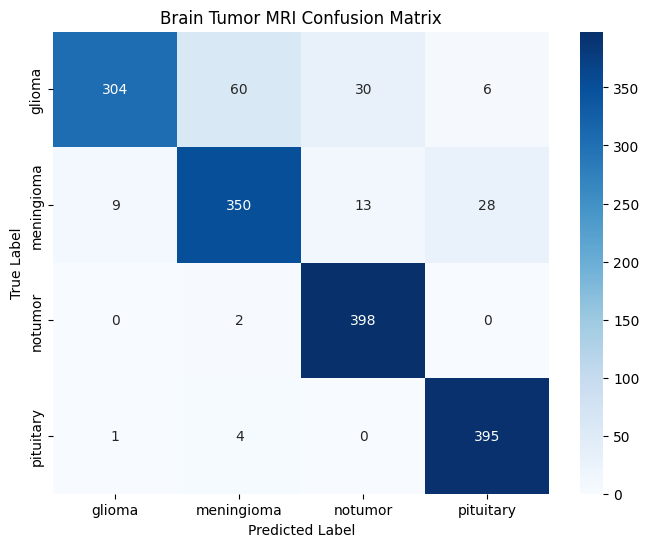

In [9]:
y_true = np.concatenate([y for x, y in test_ds], axis=0)
y_pred = np.argmax(model.predict(test_ds), axis=1)

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Brain Tumor MRI Confusion Matrix")
plt.show()


In [13]:
import cv2
import gradio as gr
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import tensorflow as tf


def make_gradcam_heatmap(img_array, full_model):
    # 1. Grab the DenseNet121 sub-model and final activation layer
    base_model_layer = full_model.get_layer("densenet121")
    last_conv_layer = base_model_layer.get_layer("relu")

    grad_model = tf.keras.Model(
        inputs=base_model_layer.input,
        outputs=[last_conv_layer.output, base_model_layer.output],
    )

    # 2. Preprocess image for DenseNet121
    preprocessed_img = tf.keras.applications.densenet.preprocess_input(
        tf.convert_to_tensor(img_array, dtype=tf.float32)
    )

    # 3. Record gradients with respect to the last convolutional layer
    with tf.GradientTape() as tape:
        conv_outputs, base_features = grad_model(
            preprocessed_img, training=False
        )
        tape.watch(conv_outputs)

        x = full_model.get_layer("global_pool")(base_features)
        preds = full_model.get_layer("output_dense")(x)

        # Use tf.squeeze so preds becomes a 1D tensor of length 4
        preds_1d = tf.squeeze(preds)
        top_pred_index = tf.argmax(preds_1d)
        top_class_channel = preds_1d[top_pred_index]

    # 4. Compute gradients and pool across spatial dimensions
    grads = tape.gradient(top_class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # 5. Weight feature maps and normalize (squeeze batch dim)
    conv_outputs_3d = tf.squeeze(conv_outputs, axis=0)
    heatmap = tf.reduce_sum(
        tf.multiply(pooled_grads, conv_outputs_3d), axis=-1
    )
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()


def overlay_heatmap(original_pil_img, heatmap, alpha=0.45):
    img = np.array(original_pil_img.convert("RGB").resize((224, 224)))
    heatmap_resized = cv2.resize(heatmap, (224, 224))
    heatmap_uint8 = np.uint8(255 * heatmap_resized)

    jet = plt.get_cmap("jet")
    jet_colors = jet(np.arange(256))[:, :3]
    jet_heatmap = np.uint8(255 * jet_colors[heatmap_uint8])

    superimposed = cv2.addWeighted(img, 1 - alpha, jet_heatmap, alpha, 0)
    return Image.fromarray(superimposed)


def predict_with_gradcam(input_image):
    if input_image is None:
        return None, None

    img = input_image.convert("RGB").resize((224, 224))
    img_array = np.expand_dims(np.array(img, dtype=np.float32), axis=0)

    # .flatten() turns shape (1, 4) into a clean 1D array of 4 floats
    predictions = model.predict(img_array, verbose=0).flatten()
    confidences = {
        class_names[i]: float(predictions[i]) for i in range(len(class_names))
    }

    heatmap = make_gradcam_heatmap(img_array, model)
    heatmap_image = overlay_heatmap(input_image, heatmap)

    return confidences, heatmap_image


interface = gr.Interface(
    fn=predict_with_gradcam,
    inputs=gr.Image(type="pil", label="Upload Brain MRI Scan"),
    outputs=[
        gr.Label(num_top_classes=4, label="Tumor Classification Results"),
        gr.Image(type="pil", label="Grad-CAM Attention Heatmap (Red = Focus)"),
    ],
    title="Explainable Brain Tumor MRI Classifier (DenseNet121 + Grad-CAM)",
    description="Upload a brain MRI scan to predict tumor type and visualize the exact region influencing the AI's decision.",
)

interface.launch(debug=True)


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://213da43095ec765c74.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7861 <> https://213da43095ec765c74.gradio.live
